In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,)

In [12]:
train_data=fetch_20newsgroups(
    subset="train",
    remove=("headers","footers","quotes")
)

In [13]:
test_data=fetch_20newsgroups(
    subset="test",
    remove=("headers","footers","quotes")
)

In [14]:
x_train_text=train_data.data
y_train=train_data.target
x_test_text=test_data.data
y_test=test_data.target
class_names=train_data.target_names

In [15]:
print("training documnet :",len(x_train_text))
print("testing document is :",len(x_test_text))
print("number of classes ",len(class_names))

training documnet : 11314
testing document is : 7532
number of classes  20


In [16]:
vectorizer = CountVectorizer(
    stop_words="english",
    min_df=2
)

x_train = vectorizer.fit_transform(x_train_text)

x_test = vectorizer.transform(x_test_text)

In [17]:
print("training feature matrix",x_train.shape)
print("testing feature matrix",x_test.shape)

training feature matrix (11314, 39115)
testing feature matrix (7532, 39115)


In [18]:
mnb=MultinomialNB()
mnb.fit(
    x_train,
    y_train
)
y_pred_mnb=mnb.predict(x_test)

In [19]:
binary_vectorizer=CountVectorizer(
    stop_words="english",
    min_df=2,
    binary=True
)

x_train_binary= binary_vectorizer.fit_transform(
    x_train_text
)

x_test_binary=binary_vectorizer.transform(
    x_test_text
)

In [20]:
bnb=BernoulliNB()
bnb.fit(
    x_train_binary,
    y_train
)
y_pred_bnb=bnb.predict(
    x_test_binary
)

In [21]:
bnb=BernoulliNB()
bnb.fit(x_train_binary,
        y_train)
y_pred_bnb=bnb.predict(
    x_test_binary
)

In [22]:
results=pd.DataFrame({
    "Model":[
        "Multinomial NB",
        "Bernoulli NB"],
    "Accuracy":[
        accuracy_score(y_test,y_pred_mnb),
        accuracy_score(y_test,y_pred_bnb)
    ],
    "Precision score":[
        precision_score(y_test,y_pred_mnb,average="macro"),
        precision_score(y_test,y_pred_bnb,average="macro")],
    "Recall":[
        recall_score(y_test,y_pred_mnb,average="macro"),
        recall_score(y_test,y_pred_bnb,average="macro")],
    "F1-score":[
        f1_score(y_test,y_pred_mnb,average="macro"),
        f1_score(y_test,y_pred_bnb,average="macro")]
})
results

,Model,Accuracy,Precision score,Recall,F1-score
0,Multinomial NB,0.651089,0.634470,0.636933,0.617859
1,Bernoulli NB,0.485130,0.616678,0.469434,0.467865


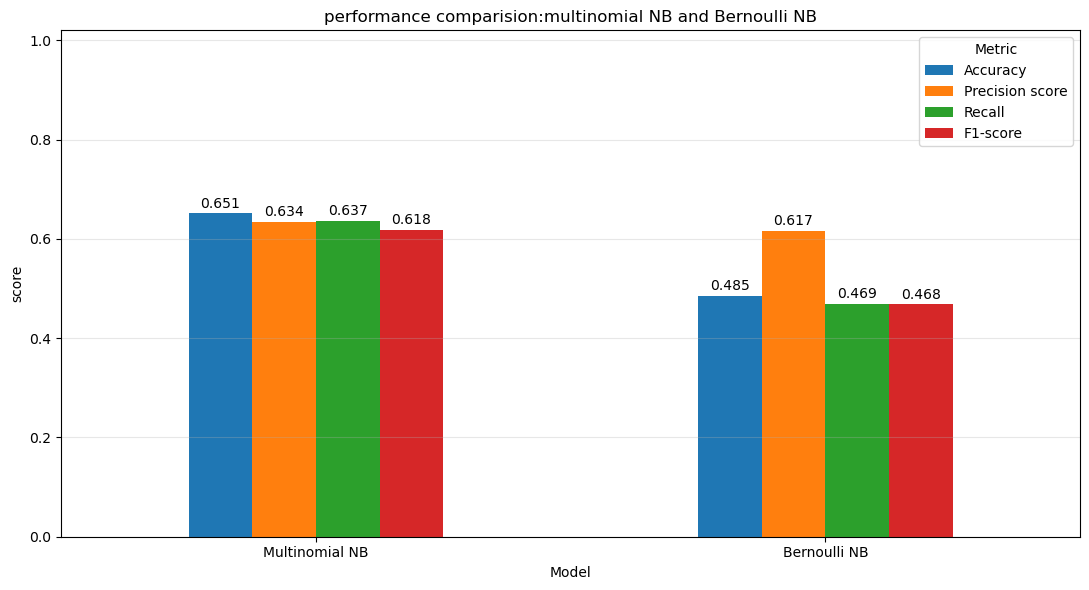

In [35]:
results_metrics=results[
   ["Model", "Accuracy", "Precision score", "Recall", "F1-score"]
    ]
ax=results_metrics.set_index("Model").plot(
    kind="bar",
    figsize=(11,6)
)
plt.title("performance comparision:multinomial NB and Bernoulli NB")
plt.xlabel("Model")
plt.ylabel("score")
plt.ylim(0,1.02)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(
    axis="y",
    alpha=0.3)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2)
plt.tight_layout()
plt.show()